In [1]:
import polars as pl
import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

print("Library berhasil diimpor.")
print("Versi Polars:", pl.__version__)

Library berhasil diimpor.
Versi Polars: 2.0.0


In [2]:
DATA_PATH = "/home/jovyan/work/data/processed/cosmopedia_id_clean.parquet"

file = Path(DATA_PATH)

if file.exists():
    print("Dataset ditemukan.")
    print("Lokasi:", DATA_PATH)
    print(f"Ukuran file: {file.stat().st_size / (1024**2):.2f} MB")
else:
    raise FileNotFoundError(
        "Dataset hasil cleaning tidak ditemukan. "
        "Pastikan notebook 02 sudah dijalankan."
    )

df = pl.read_parquet(DATA_PATH)

print("\nJumlah baris:", df.height)
print("Jumlah kolom:", df.width)

display(df.head(10))

Dataset ditemukan.
Lokasi: /home/jovyan/work/data/processed/cosmopedia_id_clean.parquet
Ukuran file: 154.10 MB

Jumlah baris: 120068
Jumlah kolom: 9


id,prompt,text,token_length,audience,format,seed_data,datasheet_global_id,created_at
i64,str,str,i64,str,str,str,i64,str
1,"""Berikut adalah ekstrak dari ha…","""Dahulu kala, ada sebuah agen y…",699,"""children""","""story""","""fineweb""",1,"""2026-02-18 07:35:54"""
24,"""Berikut kutipan dari sebuah ha…","""Suatu ketika, di sebuah negeri…",137,"""children""","""story""","""fineweb""",2,"""2026-02-18 08:19:23"""
25,"""Berikut kutipan dari sebuah ha…","""Di kota Popville, hiduplah ban…",93,"""children""","""story""","""fineweb""",3,"""2026-02-18 08:19:23"""
26,"""Berikut kutipan tentang chipmu…","""Di sebuah lingkungan yang tena…",76,"""children""","""story""","""fineweb""",4,"""2026-02-18 08:19:23"""
27,"""Berikut kutipan tentang terapi…","""Timmy pernah merasa sangat sed…",88,"""children""","""story""","""fineweb""",5,"""2026-02-18 08:19:23"""
28,"""Berikut kutipan tentang invest…","""Di negeri yang luas, seorang b…",57,"""children""","""story""","""fineweb""",6,"""2026-02-18 08:19:23"""
29,"""Berikut kutipan tentang kesela…","""Alice: Hei Bob, kalau jalan di…",61,"""children""","""dialogue""","""fineweb""",7,"""2026-02-18 08:19:23"""
30,"""Berikut kutipan tentang makana…","""Emma suka makanan manis. Bu Gu…",64,"""children""","""story""","""fineweb""",8,"""2026-02-18 08:19:23"""
31,"""Berikut kutipan tentang penyem…","""Alice: Aku sering susah tidur …",48,"""children""","""dialogue""","""fineweb""",9,"""2026-02-18 08:19:23"""


In [3]:
print("Schema Dataset:")
print(df.schema)

print("\nInformasi Dataset:")
print(f"Jumlah baris  : {df.height:,}")
print(f"Jumlah kolom  : {df.width}")
print(f"Nama kolom    : {df.columns}")

Schema Dataset:
Schema({'id': Int64, 'prompt': String, 'text': String, 'token_length': Int64, 'audience': String, 'format': String, 'seed_data': String, 'datasheet_global_id': Int64, 'created_at': String})

Informasi Dataset:
Jumlah baris  : 120,068
Jumlah kolom  : 9
Nama kolom    : ['id', 'prompt', 'text', 'token_length', 'audience', 'format', 'seed_data', 'datasheet_global_id', 'created_at']


In [4]:
# Statistik Deskripstif 
print("Statistik Deskriptif Dataset:")
display(df.describe())

Statistik Deskriptif Dataset:


statistic,id,prompt,text,token_length,audience,format,seed_data,datasheet_global_id,created_at
str,f64,str,str,f64,str,str,str,f64,str
"""count""",120068.0,"""120068""","""120068""",120068.0,"""120067""","""120067""","""120067""",120068.0,"""120068"""
"""null_count""",0.0,"""0""","""0""",0.0,"""1""","""1""","""1""",0.0,"""0"""
"""mean""",60057.499217,null,null,1187.939651,null,null,null,60034.5,null
"""std""",34660.791753,null,null,194.61858,null,null,null,34660.790398,null
"""min""",1.0,"""Berikut adalah cuplikan dari h…","""**1.1 Apa itu Ilmu Data?** Ba…",36.0,"""children""","""Dialogue""","""fineweb""",1.0,"""2026-02-18 07:35:54"""
"""25%""",30041.0,null,null,1065.0,null,null,null,30018.0,null
"""50%""",60058.0,null,null,1168.0,null,null,null,60035.0,null
"""75%""",90074.0,null,null,1296.0,null,null,null,90051.0,null
"""max""",120091.0,"""Write an educational story (3-…","""अगर आपको उchcha madhyamik stan…",2787.0,"""young_children""","""textbook_unconditionned_topic""","""ultrachat""",120068.0,"""2026-03-06 03:44:48"""


In [5]:
# Analisis Distribusi Audience
audience_dist = (
    df.group_by("audience")
    .agg(pl.len().alias("jumlah_data"))
    .sort("jumlah_data", descending=True)
)

display(audience_dist)

audience,jumlah_data
str,u32
"""children""",64989
"""middle_school_students""",33078
"""young_children""",22000
null,1


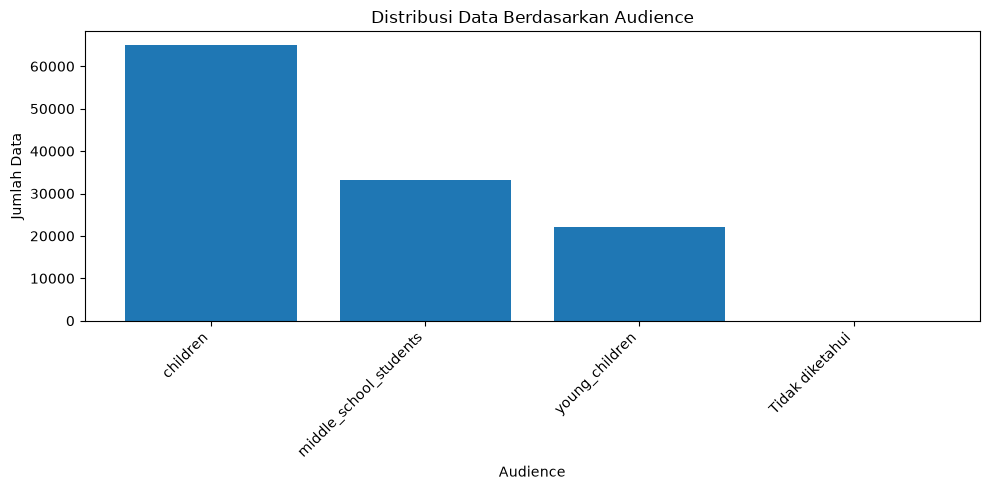

In [6]:
# Visualisasi Distribusi Audience
plot_audience = (
    audience_dist
    .with_columns(
        pl.col("audience").fill_null("Tidak diketahui")
    )
)

plt.figure(figsize=(10, 5))

plt.bar(
    plot_audience["audience"].to_list(),
    plot_audience["jumlah_data"].to_list()
)

plt.title("Distribusi Data Berdasarkan Audience")
plt.xlabel("Audience")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [7]:
# Analisis Distribusi Format
format_dist = (
    df.group_by("format")
    .agg(pl.len().alias("jumlah_data"))
    .sort("jumlah_data", descending=True)
)

display(format_dist)

format,jumlah_data
str,u32
"""story""",36230
"""dialogue""",28758
"""textbook""",24508
"""story_children""",17989
"""textbook_unconditionned_topic""",8521
"""textbook_narrative""",3562
"""e-learning_module""",498
null,1
"""Dialogue""",1


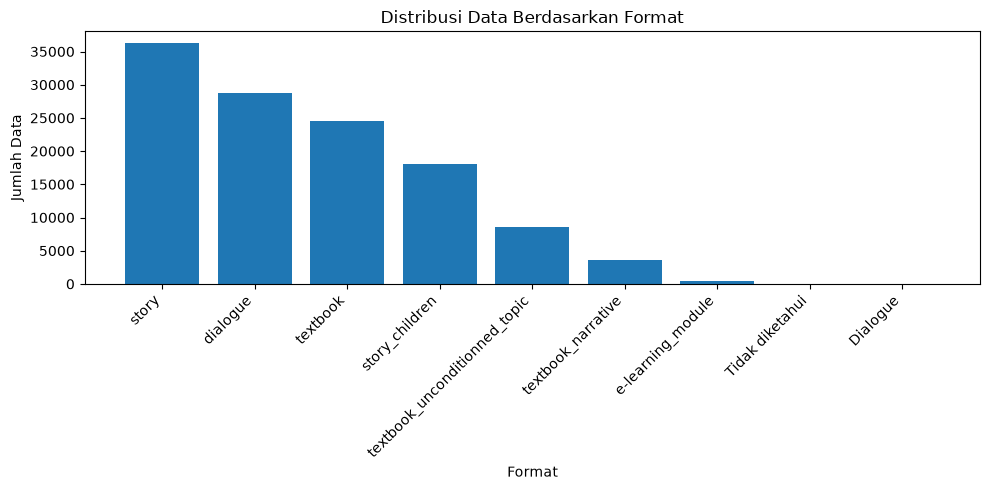

In [8]:
# Visualisasi Distribusi Format
plot_format = (
    format_dist
    .with_columns(
        pl.col("format").fill_null("Tidak diketahui")
    )
)

plt.figure(figsize=(10, 5))

plt.bar(
    plot_format["format"].to_list(),
    plot_format["jumlah_data"].to_list()
)

plt.title("Distribusi Data Berdasarkan Format")
plt.xlabel("Format")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [9]:
# Analisis Panjang Prompt dan Text
df_eda = df.with_columns([
    pl.col("prompt").str.len_chars().alias("prompt_length"),
    pl.col("text").str.len_chars().alias("text_length")
])

display(
    df_eda.select([
        "prompt_length",
        "text_length",
        "token_length"
    ]).describe()
)

statistic,prompt_length,text_length,token_length
str,f64,f64,f64
"""count""",120068.0,120068.0,120068.0
"""null_count""",0.0,0.0,0.0
"""mean""",1785.361887,2964.107364,1187.939651
"""std""",195.325867,790.960282,194.61858
"""min""",106.0,18.0,36.0
"""25%""",1715.0,2417.0,1065.0
"""50%""",1797.0,2865.0,1168.0
"""75%""",1908.0,3425.0,1296.0
"""max""",3829.0,9788.0,2787.0


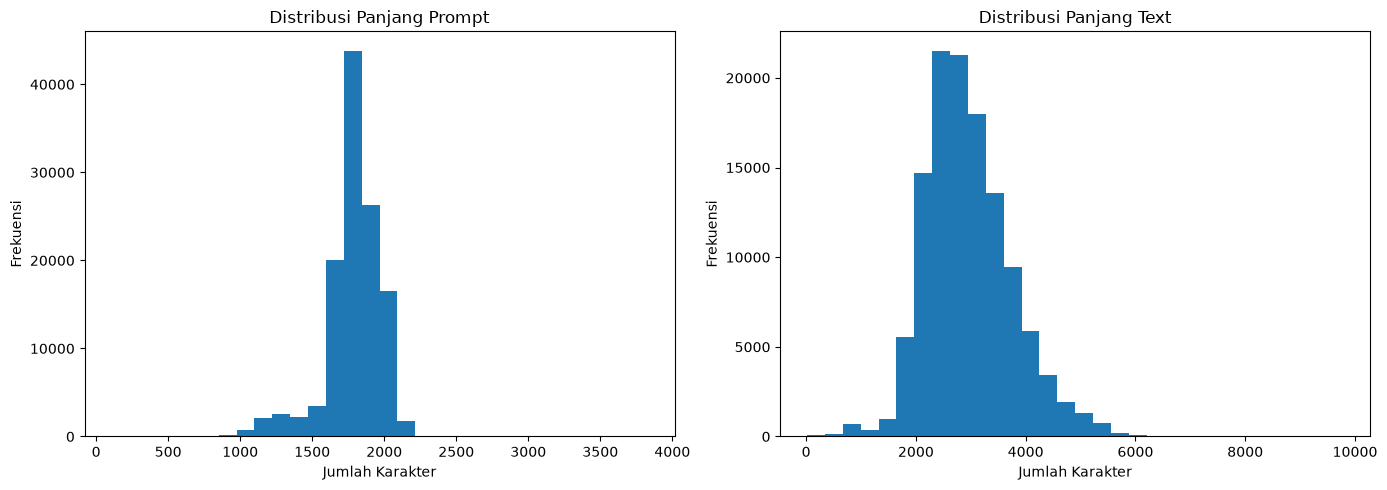

In [10]:
# Visualisasi Panjang Prompt dan Text
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    df_eda["prompt_length"].to_list(),
    bins=30
)
axes[0].set_title("Distribusi Panjang Prompt")
axes[0].set_xlabel("Jumlah Karakter")
axes[0].set_ylabel("Frekuensi")

axes[1].hist(
    df_eda["text_length"].to_list(),
    bins=30
)
axes[1].set_title("Distribusi Panjang Text")
axes[1].set_xlabel("Jumlah Karakter")
axes[1].set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()

In [11]:
# Analisis Distribusi Token Length
token_stats = df.select([
    pl.col("token_length").min().alias("minimum_token"),
    pl.col("token_length").max().alias("maksimum_token"),
    pl.col("token_length").mean().alias("rata_rata_token"),
    pl.col("token_length").median().alias("median_token"),
    pl.col("token_length").std().alias("standar_deviasi_token")
])

display(token_stats)

minimum_token,maksimum_token,rata_rata_token,median_token,standar_deviasi_token
i64,i64,f64,f64,f64
36,2787,1187.939651,1168.0,194.61858


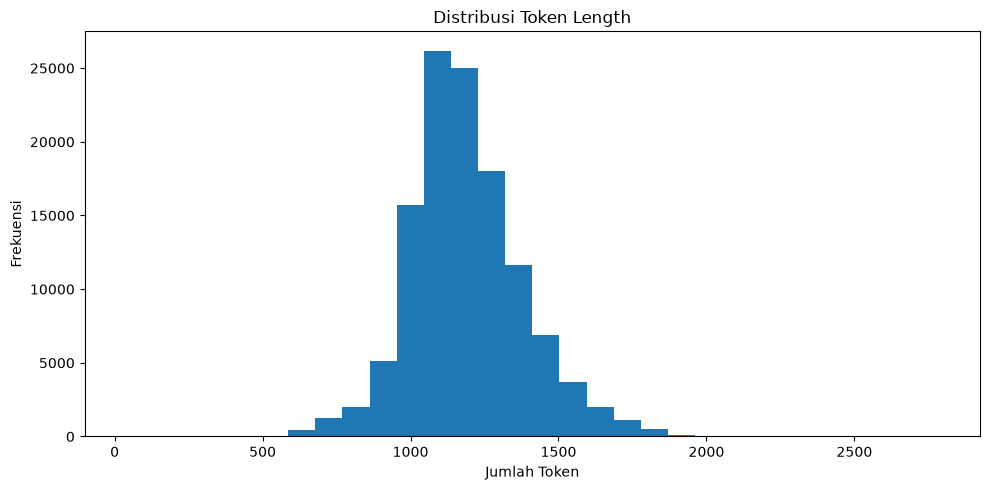

In [12]:
# Visualisasi Token Length
plt.figure(figsize=(10, 5))

plt.hist(
    df["token_length"].drop_nulls().to_list(),
    bins=30
)

plt.title("Distribusi Token Length")
plt.xlabel("Jumlah Token")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

In [13]:
# Analisis Seed Data
seed_dist = (
    df.group_by("seed_data")
    .agg(pl.len().alias("jumlah_data"))
    .sort("jumlah_data", descending=True)
)

display(seed_dist.head(10))

seed_data,jumlah_data
str,u32
"""fineweb""",98018
"""openhermes2.5""",10021
"""ultrachat""",7968
"""stanford""",3562
"""openstax""",498
null,1


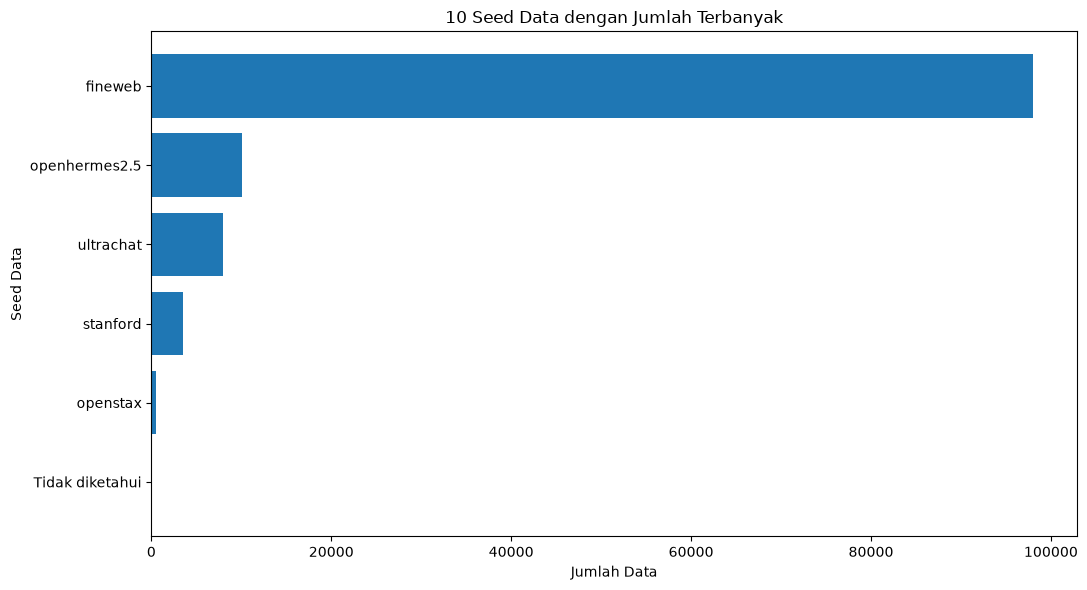

In [14]:
# Visualisasi Top 10 Seed Data
top_seed = (
    seed_dist
    .head(10)
    .with_columns(
        pl.col("seed_data").fill_null("Tidak diketahui")
    )
    .sort("jumlah_data")
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_seed["seed_data"].to_list(),
    top_seed["jumlah_data"].to_list()
)

plt.title("10 Seed Data dengan Jumlah Terbanyak")
plt.xlabel("Jumlah Data")
plt.ylabel("Seed Data")
plt.tight_layout()
plt.show()

In [15]:
# Analisis Hubungan Panjang Text dan Token Length
correlation = df_eda.select(
    pl.corr("text_length", "token_length")
).item()

print("Korelasi Panjang Text dan Token Length:", correlation)

Korelasi Panjang Text dan Token Length: 0.9678906547395728


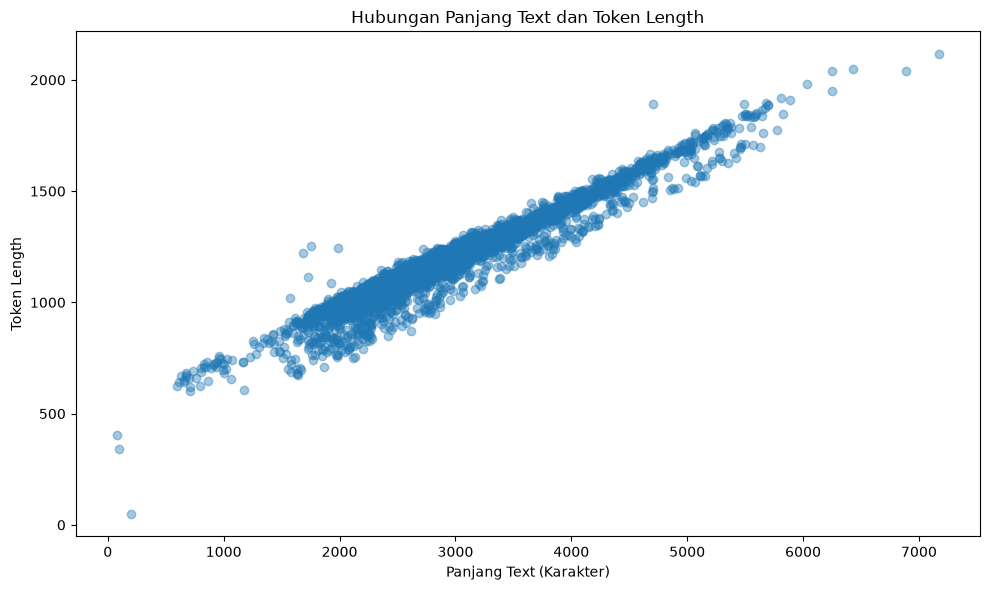

In [16]:
# Visualisasi Hubungan Text dan Token Length
sample_size = min(5000, df_eda.height)

sample_df = df_eda.sample(
    n=sample_size,
    seed=42
)

plt.figure(figsize=(10, 6))

plt.scatter(
    sample_df["text_length"].to_list(),
    sample_df["token_length"].to_list(),
    alpha=0.4
)

plt.title("Hubungan Panjang Text dan Token Length")
plt.xlabel("Panjang Text (Karakter)")
plt.ylabel("Token Length")
plt.tight_layout()
plt.show()

In [17]:
# Analisis Menggunakan DuckDB
con = duckdb.connect()

duckdb_summary = con.execute("""
    SELECT
        COUNT(*) AS jumlah_baris,
        COUNT(DISTINCT id) AS jumlah_id_unik,
        AVG(token_length) AS rata_rata_token,
        MIN(token_length) AS minimum_token,
        MAX(token_length) AS maksimum_token
    FROM df
""").fetchdf()

display(duckdb_summary)

,jumlah_baris,jumlah_id_unik,rata_rata_token,minimum_token,maksimum_token
0,120068,120068,1187.939651,36,2787


In [18]:
# Query Distribusi Audience dengan DuckDB
duckdb_audience = con.execute("""
    SELECT
        audience,
        COUNT(*) AS jumlah_data
    FROM df
    GROUP BY audience
    ORDER BY jumlah_data DESC
""").fetchdf()

display(duckdb_audience)

,audience,jumlah_data
0,children,64989
1,middle_school_students,33078
2,young_children,22000
3,NaN,1


In [19]:
# Query Distribusi Format dengan DuckDB
duckdb_format = con.execute("""
    SELECT
        format,
        COUNT(*) AS jumlah_data
    FROM df
    GROUP BY format
    ORDER BY jumlah_data DESC
""").fetchdf()

display(duckdb_format)

,format,jumlah_data
0,story,36230
1,dialogue,28758
2,textbook,24508
3,story_children,17989
4,textbook_unconditionned_topic,8521
5,textbook_narrative,3562
6,e-learning_module,498
7,NaN,1
8,Dialogue,1


In [20]:
# Ringkasan Hasil Analisis
print("RINGKASAN HASIL EDA")
print("=" * 40)

print(f"Jumlah data       : {df.height:,}")
print(f"Jumlah kolom      : {df.width}")

print("\nAudience terbanyak:")
display(audience_dist.head(5))

print("\nFormat terbanyak:")
display(format_dist.head(5))

print("\nSeed data terbanyak:")
display(seed_dist.head(5))

print("\nStatistik token:")
display(token_stats)

print("\nKorelasi text length dan token length:")
print(correlation)

RINGKASAN HASIL EDA
Jumlah data       : 120,068
Jumlah kolom      : 9

Audience terbanyak:


audience,jumlah_data
str,u32
"""children""",64989
"""middle_school_students""",33078
"""young_children""",22000
null,1



Format terbanyak:


format,jumlah_data
str,u32
"""story""",36230
"""dialogue""",28758
"""textbook""",24508
"""story_children""",17989
"""textbook_unconditionned_topic""",8521



Seed data terbanyak:


seed_data,jumlah_data
str,u32
"""fineweb""",98018
"""openhermes2.5""",10021
"""ultrachat""",7968
"""stanford""",3562
"""openstax""",498



Statistik token:


minimum_token,maksimum_token,rata_rata_token,median_token,standar_deviasi_token
i64,i64,f64,f64,f64
36,2787,1187.939651,1168.0,194.61858



Korelasi text length dan token length:
0.9678906547395728


# Kesimpulan dan Insight EDA

Berdasarkan hasil Exploratory Data Analysis (EDA) terhadap dataset Cosmopedia Indonesia, diperoleh beberapa temuan mengenai karakteristik dan distribusi data. Dataset memiliki 120.068 baris dan 9 kolom yang mencakup informasi prompt, teks, jumlah token, audience, format, dan metadata lainnya.

Hasil analisis menunjukkan bahwa:

1. **Distribusi Audience**  
   Kategori audience yang paling dominan adalah `children` dengan jumlah 64.989 data, diikuti `middle_school_students` sebanyak 33.078 data dan `young_children` sebanyak 22.000 data. Hal ini menunjukkan bahwa sebagian besar konten dalam dataset ditujukan untuk kelompok anak-anak.

2. **Distribusi Format**  
   Format yang paling banyak ditemukan adalah `story` sebanyak 36.230 data, diikuti `dialogue` sebanyak 28.758 data dan `textbook` sebanyak 24.508 data. Hasil ini menunjukkan bahwa format cerita merupakan jenis konten yang paling dominan dalam dataset.

3. **Distribusi Token Length**  
   Panjang token memiliki nilai minimum 36 dan maksimum 2.787 token. Rata-rata panjang token adalah 1.187,94, sedangkan mediannya sebesar 1.168. Hasil ini menunjukkan bahwa sebagian besar data memiliki panjang token yang berada di sekitar nilai rata-rata dan median tersebut.

4. **Hubungan Panjang Text dan Token Length**  
   Hasil perhitungan korelasi Pearson menunjukkan nilai sebesar 0,9679. Nilai tersebut menunjukkan hubungan linear positif yang sangat kuat antara jumlah karakter pada kolom text dan jumlah token. Dengan demikian, teks yang memiliki jumlah karakter lebih banyak cenderung memiliki jumlah token yang lebih tinggi.

5. **Temuan Kualitas Kategori Data**  
   Ditemukan satu nilai kosong pada kolom audience dan satu nilai kosong pada kolom format. Selain itu, terdapat variasi penulisan kategori `dialogue` dan `Dialogue` yang perlu diperhatikan karena perbedaan huruf kapital dapat menyebabkan kategori yang sama terbaca sebagai dua kategori berbeda.

Secara keseluruhan, hasil EDA memberikan gambaran bahwa dataset Cosmopedia Indonesia didominasi oleh konten untuk kelompok anak-anak dengan format cerita sebagai kategori konten terbanyak. Selain itu, terdapat hubungan yang sangat kuat antara panjang teks dan jumlah token. Temuan ini dapat digunakan sebagai dasar untuk memahami karakteristik dataset dan menentukan pengolahan data lebih lanjut.